# PINNfluence: the paper's drift-diffusion analysis (DeepXDE)

This notebook recreates the drift-diffusion experiment from the main text with the same DeepXDE-based machinery (`pinnfluence/`) that produced all results in the paper. It is the place to reproduce or extend what the paper covers.

We feature:
- Training the model (well-trained and poorly-trained configs, as in the paper)
- Visualizing predictions
- Calculating influences for any pair of loss terms ($f$ and $L$ in the paper)
- Visualizations of point-wise influences

Note that all calculations should run fairly quick.

> To apply PINNfluence to your own PyTorch PINN, use the plain-PyTorch demo in [`pinnfluence_torch/demo.ipynb`](../pinnfluence_torch/demo.ipynb) instead. It does not depend on DeepXDE and is the practical route.

In [1]:
import deepxde as dde
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import torch

# Import pinnfluence modules
from pinnfluence.utils.defaults import PROBLEMS, BAD_PROBLEMS
from pinnfluence.utils.utils import (
    visualize_influence_comparison,
    visualize_predictions_comparison,
    load_problem,
    set_default_device,
)
from pinnfluence.precalculate_influences import main as calc_influences

if torch.cuda.is_available():
    set_default_device('cuda')
else:
    set_default_device('cpu')

Using backend: pytorch
Other supported backends: tensorflow.compat.v1, tensorflow, jax, paddle.
paddle supports more examples now and is recommended.


Using CUDA


## Training for good and bad conigs 

In [2]:
problem_name = 'drift_diffusion'
model_zoo = Path('../model_zoo/')
seed = 0

In [3]:
# good model
model, data, model_name, chkpt_path = load_problem(
    problem_name=problem_name,
    params_dict=PROBLEMS[problem_name],
    seed=seed,
    load_path=model_zoo / f"{problem_name}_float64",
    force_reinitialize=False
)

if chkpt_path is not None:
    print(f'Loaded good model "{model_name}" from {chkpt_path}')
else:
    print(f'Initialized new model "{model_name}"')

    from pinnfluence.pretrain import main as train_model 

    train_model(
        problem_name=problem_name,
        n_iterations=PROBLEMS[problem_name]['n_iterations'],
        n_iterations_lbfgs=PROBLEMS[problem_name]['n_iterations_lbfgs'],
        num_domain=PROBLEMS[problem_name]['num_domain'],
        num_boundary=PROBLEMS[problem_name]['num_boundary'],
        num_initial=PROBLEMS[problem_name]['num_initial'],
        layers=PROBLEMS[problem_name]['layers'],
        seed=seed,
        save_path=str(model_zoo / f"{problem_name}_float64"),
        use_float64=True,
    )


Set the default float type to float64
load_path: ../model_zoo/drift_diffusion_float64
num_test_domain: 9008, num_test_boundary: 666, num_test_initial: 666
data.holdout_test_x.shape: (11006, 2)
Force reinit: False, checkpoint_path: None
Loading checkpoint under ../model_zoo/drift_diffusion_float64 under name: drift_diffusion_adam_15000_adam_5000_lbfgs_1000_domain_100_boundary_100_initial_3_x_64_hidden_float64_True_0_soft
Compiling model...


/home/krasowski/projects/pinnfluence_git_torch/.venv/lib/python3.13/site-packages/pinnfluence/utils/io.py:22: UserWarning: No checkpoint found for 'drift_diffusion_adam_15000_adam_5000_lbfgs_1000_domain_100_boundary_100_initial_3_x_64_hidden_float64_True_0_soft' under '../model_zoo/drift_diffusion_float64'. Model will use random initialization!
  return construct_problem(


'compile' took 0.680088 s

Initialized new model "drift_diffusion_adam_15000_adam_5000_lbfgs_1000_domain_100_boundary_100_initial_3_x_64_hidden_float64_True_0_soft"
Using CPU
SOFT CONSTRAINING
Set the default float type to float64
Set the default float type to float64
load_path: None
num_test_domain: 9008, num_test_boundary: 666, num_test_initial: 666
data.holdout_test_x.shape: (11006, 2)
Force reinit: True, checkpoint_path: None
Compiling model...
'compile' took 0.000097 s



Training: 100%|██████████| 15000/15000 [03:14<00:00, 77.29it/s, train_loss=4.67e-03, valid_loss=4.08e-03, test_loss=1.77e-03, l2re=8.08e-02, mse=6.14e-04]

Compiling model...
'compile' took 0.000143 s




Training: 100%|██████████| 5000/5000 [01:52<00:00, 44.59it/s, train_loss=6.78e-05, valid_loss=6.79e-05, test_loss=2.10e-05, l2re=1.05e-02, mse=1.05e-05]


In [4]:
# good model
model_bad, data_bad, model_name_bad, chkpt_path_bad = load_problem(
    problem_name=problem_name,
    params_dict=BAD_PROBLEMS[problem_name],
    seed=seed,
    load_path=model_zoo / f"{problem_name}_float64",
)

if chkpt_path_bad is not None:
    print(f'Loaded bad model "{model_name_bad}" from {chkpt_path_bad}')
else:
    print(f'Initialized new model "{model_name_bad}"')

    from pinnfluence.pretrain import main as train_model 

    train_model(
        problem_name=problem_name,
        n_iterations=BAD_PROBLEMS[problem_name]['n_iterations'],
        n_iterations_lbfgs=BAD_PROBLEMS[problem_name]['n_iterations_lbfgs'],
        num_domain=BAD_PROBLEMS[problem_name]['num_domain'],
        num_boundary=BAD_PROBLEMS[problem_name]['num_boundary'],
        num_initial=BAD_PROBLEMS[problem_name]['num_initial'],
        layers=BAD_PROBLEMS[problem_name]['layers'],
        seed=seed,
        save_path=str(model_zoo / f"{problem_name}_float64"),
        use_float64=True,
        soft_constrained=True,
    )

Set the default float type to float64
load_path: ../model_zoo/drift_diffusion_float64
num_test_domain: 8768, num_test_boundary: 666, num_test_initial: 666
data.holdout_test_x.shape: (10766, 2)
Force reinit: False, checkpoint_path: None
Loading checkpoint under ../model_zoo/drift_diffusion_float64 under name: drift_diffusion_adam_15000_adam_5000_lbfgs_200_domain_20_boundary_20_initial_3_x_64_hidden_float64_True_0_soft
Compiling model...
'compile' took 0.000080 s

Initialized new model "drift_diffusion_adam_15000_adam_5000_lbfgs_200_domain_20_boundary_20_initial_3_x_64_hidden_float64_True_0_soft"
Using CPU
SOFT CONSTRAINING
Set the default float type to float64
Set the default float type to float64
load_path: None
num_test_domain: 8768, num_test_boundary: 666, num_test_initial: 666
data.holdout_test_x.shape: (10766, 2)
Force reinit: True, checkpoint_path: None
Compiling model...
'compile' took 0.000110 s



/home/krasowski/projects/pinnfluence_git_torch/.venv/lib/python3.13/site-packages/pinnfluence/utils/io.py:22: UserWarning: No checkpoint found for 'drift_diffusion_adam_15000_adam_5000_lbfgs_200_domain_20_boundary_20_initial_3_x_64_hidden_float64_True_0_soft' under '../model_zoo/drift_diffusion_float64'. Model will use random initialization!
  return construct_problem(
Training: 100%|██████████| 15000/15000 [01:23<00:00, 179.23it/s, train_loss=6.20e-04, valid_loss=2.66e+00, test_loss=2.42e+00, l2re=8.91e-01, mse=7.17e-02]

Compiling model...
'compile' took 0.000121 s




Training: 100%|██████████| 5000/5000 [01:06<00:00, 75.54it/s, train_loss=1.12e-06, valid_loss=3.50e+00, test_loss=3.22e+00, l2re=1.29e+00, mse=1.51e-01]


## Visualizing Predictions

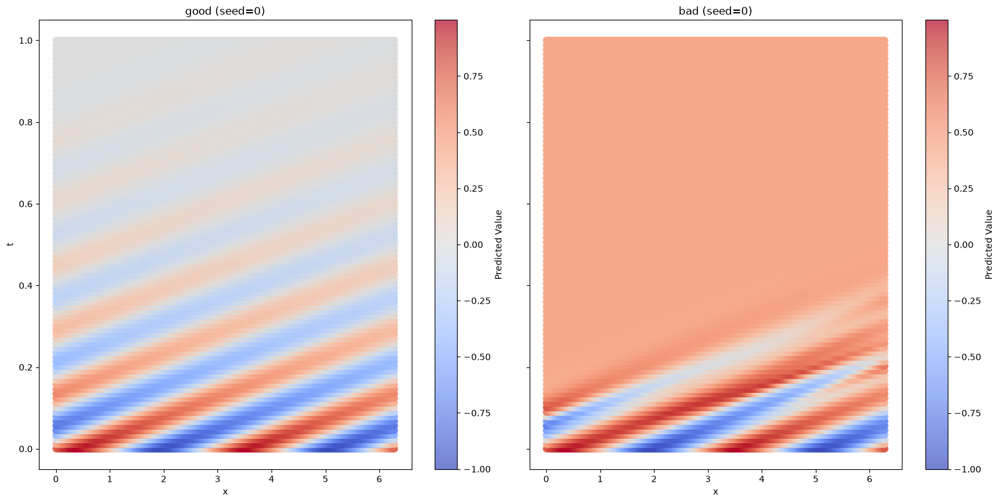

In [5]:
# Visualize predictions comparison
fig = visualize_predictions_comparison(
    problem_name=problem_name,
    seed=seed,
    figsize=(16, 8),
    model_zoo_base=str(model_zoo),
)
plt.tight_layout()
plt.show()

## Notes

You can also train other models. Just change the problem name to one of the following:

- `diffusion` (called heat in the paper)
- `allen_cahn`
- `burgers`
- `wave`
- `poisson_disk`
- `navier_stokes_nd`

## Calculating Influences

In the demo we provide code for the model prediction with respect to the total loss. 

However you can change both the left term (called $f$ in the paper) as well as the right term (called $L$ or $L_i$ in the paper) as you wish. 

Allowed right terms are any of the loss functions which are encoded as follows:

- `total_loss` = The composite PINN loss (including all individual loss terms)
- `pde_total` = PDE residual 
- `pde_0` = same as PDE residual in this case (since we only have one, however for the Navier-Stokes model you may also use `pde_1`, `pde_2`)
- `bc_total` = BC loss (all together)
- `bc_0` = initial condition
- `bc_1` = periodic boundary condition ($x=0$)
- `bc_2` = periodic boundary condition ($x=2\pi$)

Allowed left terms are any of the above and `output_0` 

> For the Navier-Stokes model you may again also use `output_1` and `output_2`

### Influences for Good Model

In [6]:
# adjust if needed 
left_term = 'output_0'
right_term = 'total_loss'

calc_influences(
    left=left_term,
    right=right_term,
    problem_name=problem_name,
    save_path=str(model_zoo / f"{problem_name}_float64"),
    load_path=str(model_zoo / f"{problem_name}_float64"),
    n_candidate_points=10_000,
    layers=PROBLEMS[problem_name]['layers'],
    num_domain=PROBLEMS[problem_name]['num_domain'],
    num_boundary=PROBLEMS[problem_name]['num_boundary'],
    num_initial=PROBLEMS[problem_name]['num_initial'],
    n_iterations=PROBLEMS[problem_name]['n_iterations'],
    n_iterations_lbfgs=PROBLEMS[problem_name]['n_iterations_lbfgs'],
    seed=seed,
    soft_constrained=True,
    use_float64=True,
    device='cuda' if torch.cuda.is_available() else 'cpu',
    recompute_R=True,
)

Set the default float type to float64
Using CUDA
Set the default float type to float64
load_path: ../model_zoo/drift_diffusion_float64
num_test_domain: 9008, num_test_boundary: 666, num_test_initial: 666
data.holdout_test_x.shape: (11006, 2)
Force reinit: False, checkpoint_path: None
Loading checkpoint under ../model_zoo/drift_diffusion_float64 under name: drift_diffusion_adam_15000_adam_5000_lbfgs_1000_domain_100_boundary_100_initial_3_x_64_hidden_float64_True_0_soft
Found checkpoint at ../model_zoo/drift_diffusion_float64/drift_diffusion_adam_15000_adam_5000_lbfgs_1000_domain_100_boundary_100_initial_3_x_64_hidden_float64_True_0_soft_full.pt
Best epoch: 5000
Compiling model...
'compile' took 0.000107 s

Sampled 10000 candidate points
Instantiating influence function...
Influences set shape (right side of equation): (1200, 2)
Approximating hessian


/home/krasowski/projects/pinnfluence_git_torch/.venv/lib/python3.13/site-packages/torch/autograd/graph.py:1072: UserWarning: Attempting to run cuBLAS, but there was no current CUDA context! Attempting to set the primary context... (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/cuda/CublasHandlePool.cpp:410.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


Approximation took: 5.1590564250946045
Computing influence: right=total_loss, left=output_0
Calculating influences


Using ArnoldiInfluenceFunctionPrecomputed to compute inputs_dataset. Processing batch:   0%|          | 0/10 […

Using ArnoldiInfluenceFunctionPrecomputed to compute train_dataset. Processing batch:   0%|          | 0/2 [00…

Influence calculation took: 10.21451210975647
Computed influence scores with shape: (10000, 1200)

Saved influence matrix to ../model_zoo/drift_diffusion_float64/drift_diffusion_adam_15000_adam_5000_lbfgs_1000_domain_100_boundary_100_initial_3_x_64_hidden_float64_True_0_soft_influence_scores/influences_total_loss_output_0.npz


### Influences for Bad Model

In [7]:
# adjust if needed 
left_term = 'output_0'
right_term = 'total_loss'

calc_influences(
    left=left_term,
    right=right_term,
    problem_name=problem_name,
    save_path=str(model_zoo / f"{problem_name}_float64"),
    load_path=str(model_zoo / f"{problem_name}_float64"),
    n_candidate_points=10_000,
    layers=BAD_PROBLEMS[problem_name]['layers'],
    num_domain=BAD_PROBLEMS[problem_name]['num_domain'],
    num_boundary=BAD_PROBLEMS[problem_name]['num_boundary'],
    num_initial=BAD_PROBLEMS[problem_name]['num_initial'],
    n_iterations=BAD_PROBLEMS[problem_name]['n_iterations'],
    n_iterations_lbfgs=BAD_PROBLEMS[problem_name]['n_iterations_lbfgs'],
    seed=seed,
    soft_constrained=True,
    use_float64=True,
    device='cuda' if torch.cuda.is_available() else 'cpu',
    recompute_R=True,
)

Set the default float type to float64
Using CUDA
Set the default float type to float64
load_path: ../model_zoo/drift_diffusion_float64
num_test_domain: 8768, num_test_boundary: 666, num_test_initial: 666
data.holdout_test_x.shape: (10766, 2)
Force reinit: False, checkpoint_path: None
Loading checkpoint under ../model_zoo/drift_diffusion_float64 under name: drift_diffusion_adam_15000_adam_5000_lbfgs_200_domain_20_boundary_20_initial_3_x_64_hidden_float64_True_0_soft
Found checkpoint at ../model_zoo/drift_diffusion_float64/drift_diffusion_adam_15000_adam_5000_lbfgs_200_domain_20_boundary_20_initial_3_x_64_hidden_float64_True_0_soft_full.pt
Best epoch: 5000
Compiling model...
'compile' took 0.000162 s



Sampled 10000 candidate points
Instantiating influence function...
Influences set shape (right side of equation): (240, 2)
Approximating hessian
Approximation took: 2.3900654315948486
Computing influence: right=total_loss, left=output_0
Calculating influences


Using ArnoldiInfluenceFunctionPrecomputed to compute inputs_dataset. Processing batch:   0%|          | 0/10 […

Using ArnoldiInfluenceFunctionPrecomputed to compute train_dataset. Processing batch:   0%|          | 0/1 [00…

Influence calculation took: 6.826409101486206
Computed influence scores with shape: (10000, 240)

Saved influence matrix to ../model_zoo/drift_diffusion_float64/drift_diffusion_adam_15000_adam_5000_lbfgs_200_domain_20_boundary_20_initial_3_x_64_hidden_float64_True_0_soft_influence_scores/influences_total_loss_output_0.npz


## Point-Wise Heatmaps 

Red plots will show the most influential training points for selected test point

Blue plots the influence of the closest found training point (following Appendix C.4 logic)


Visualizing influences for test point at x=0.467, t=0.696


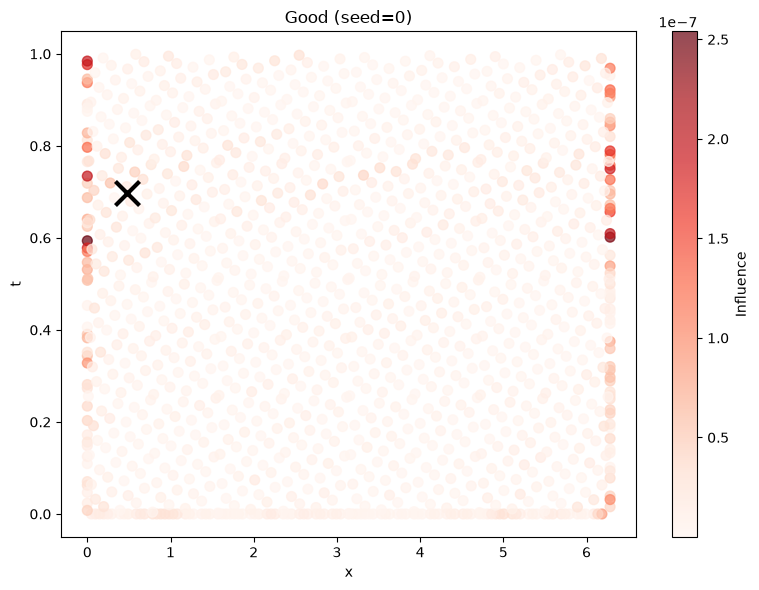

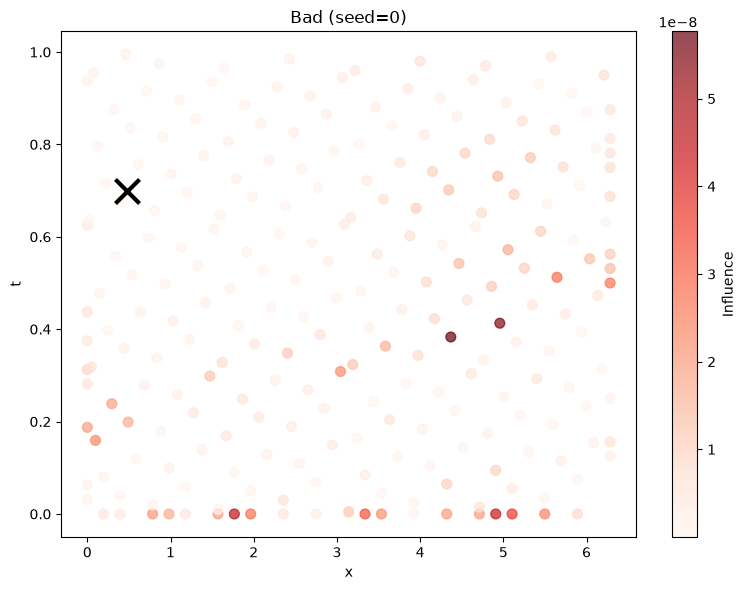

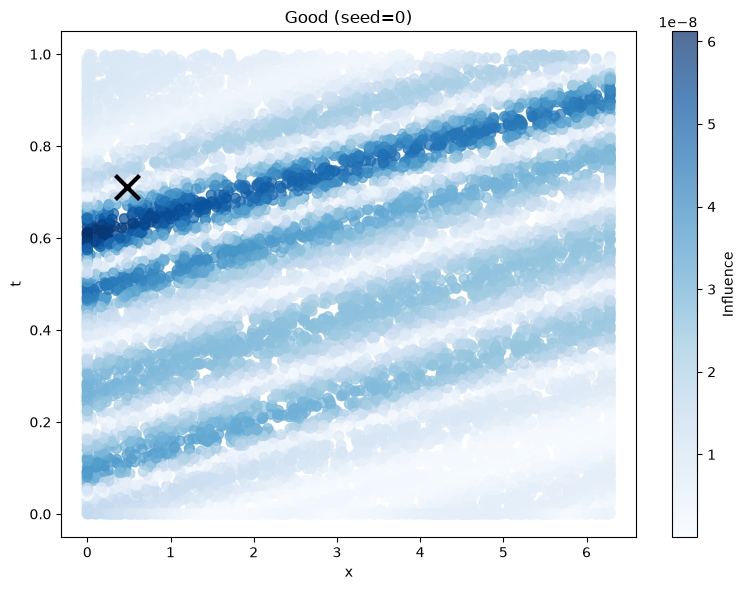

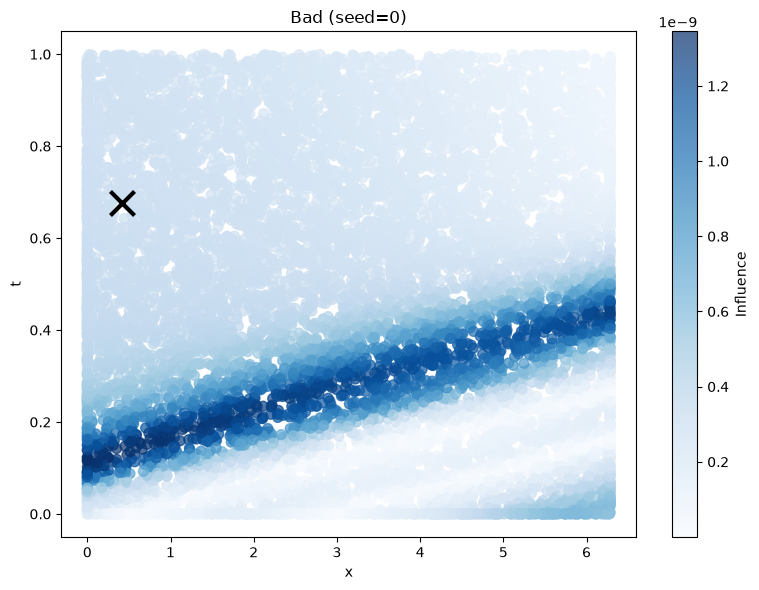


Visualizing influences for test point at x=2.747, t=0.249


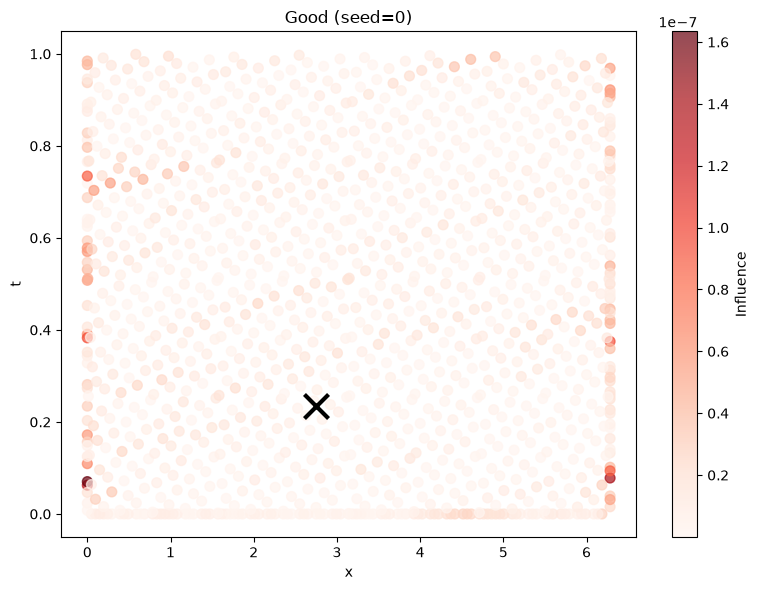

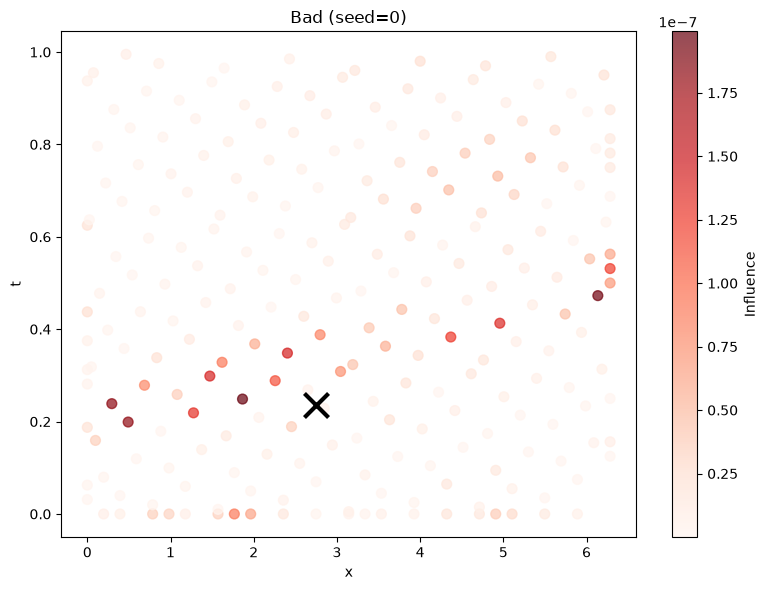

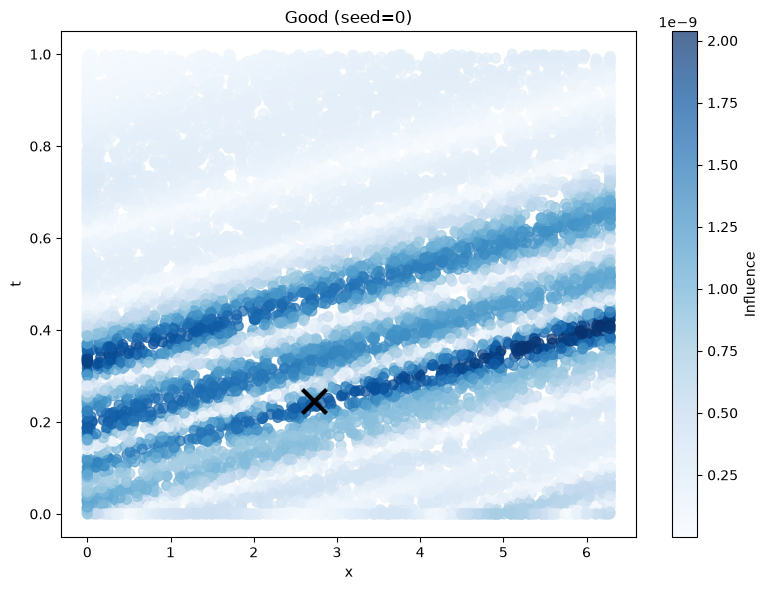

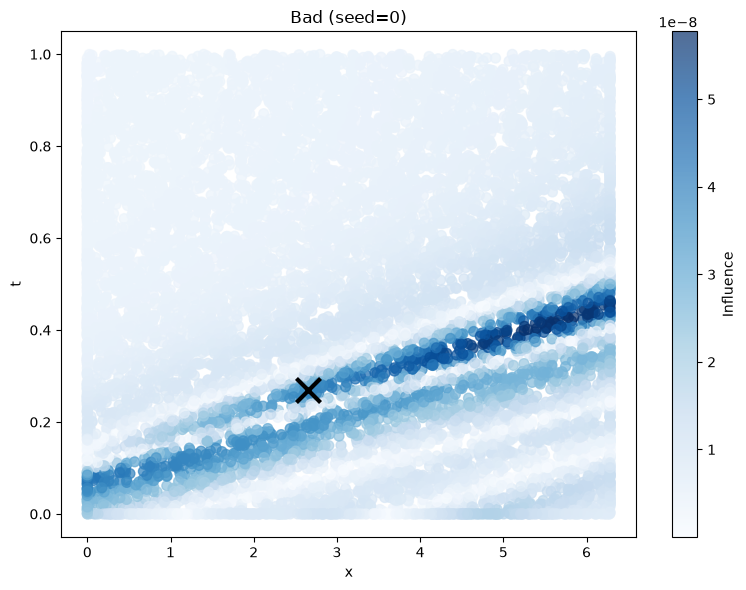


Visualizing influences for test point at x=4.250, t=0.126


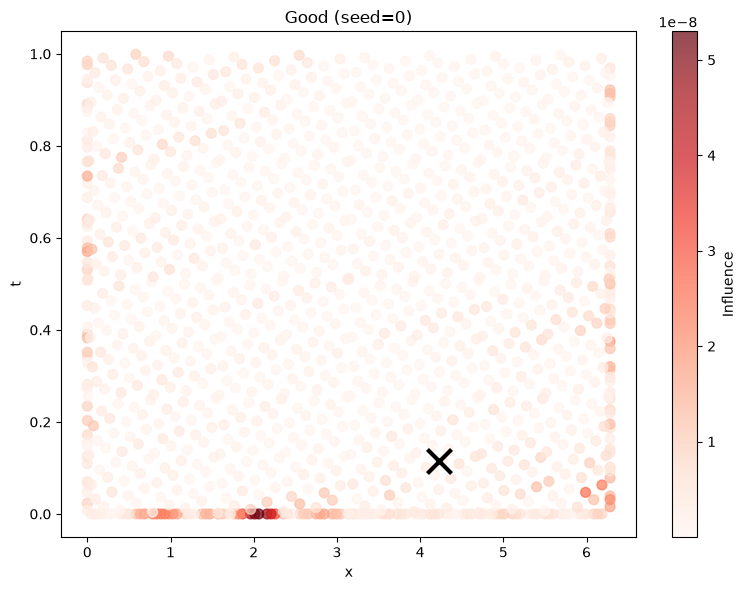

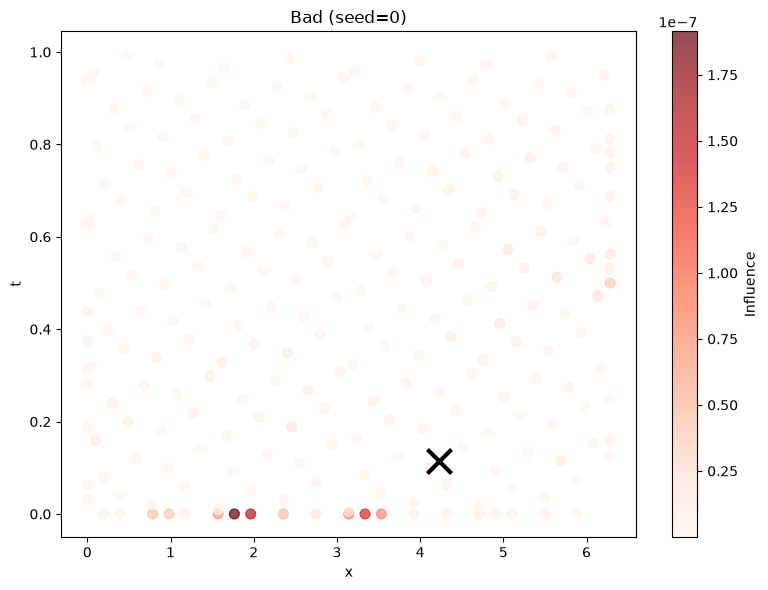

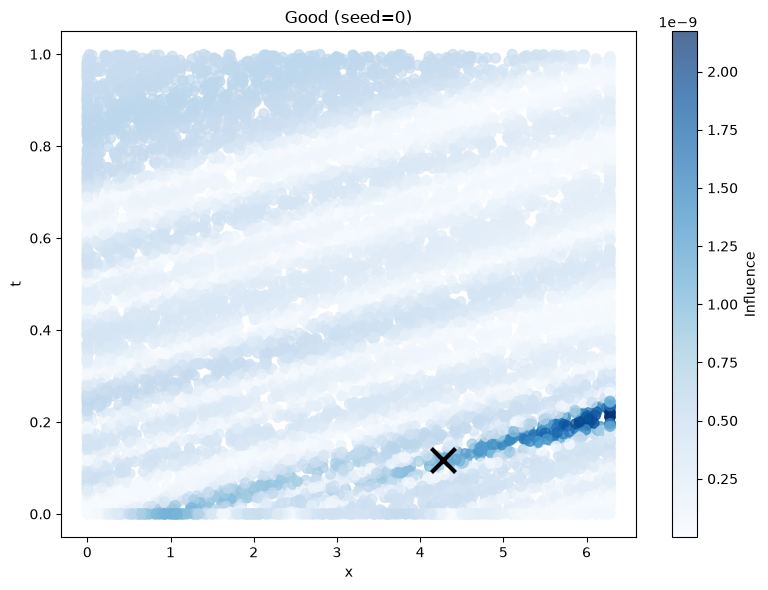

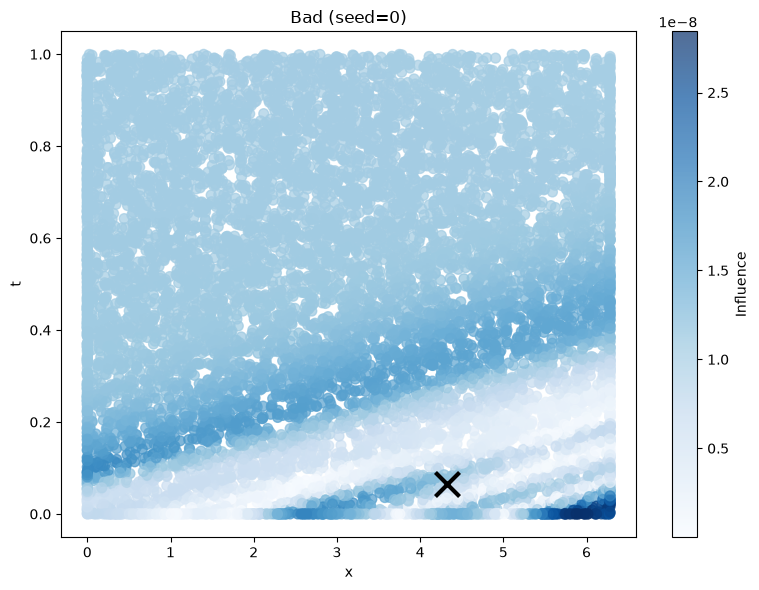


Visualizing influences for test point at x=5.393, t=0.251


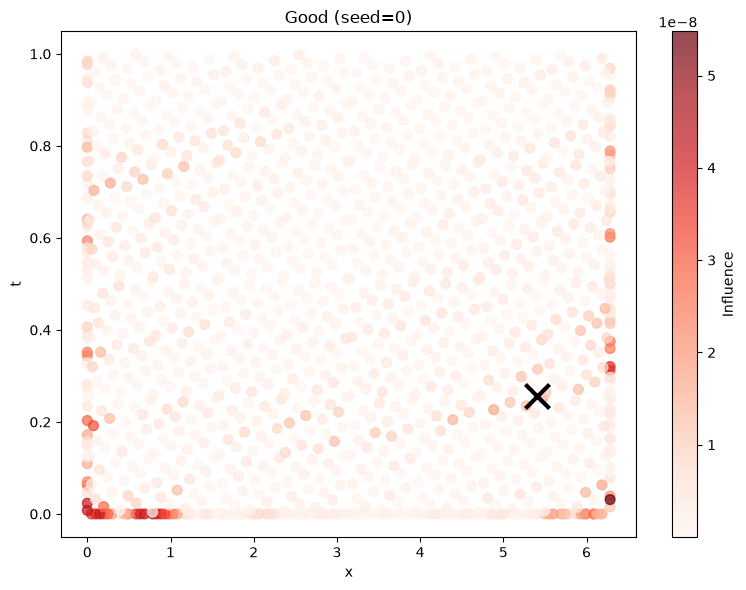

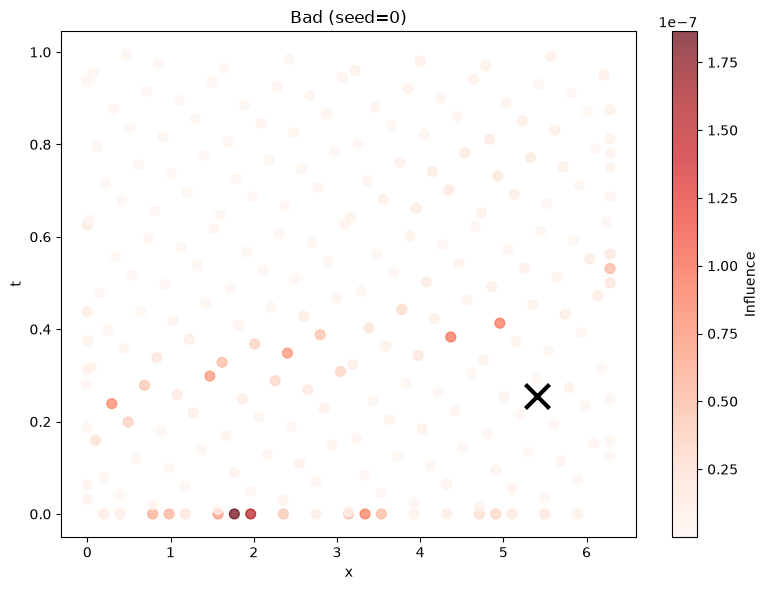

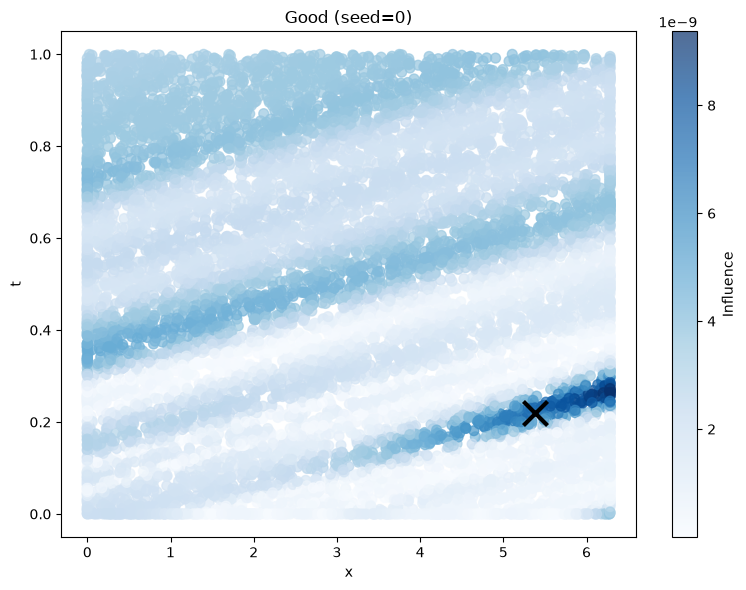

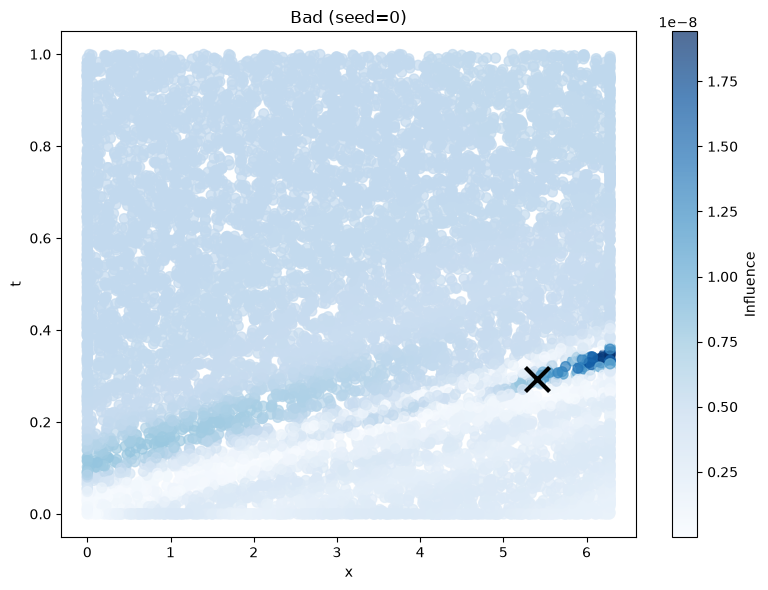


Visualizing influences for test point at x=2.271, t=0.633


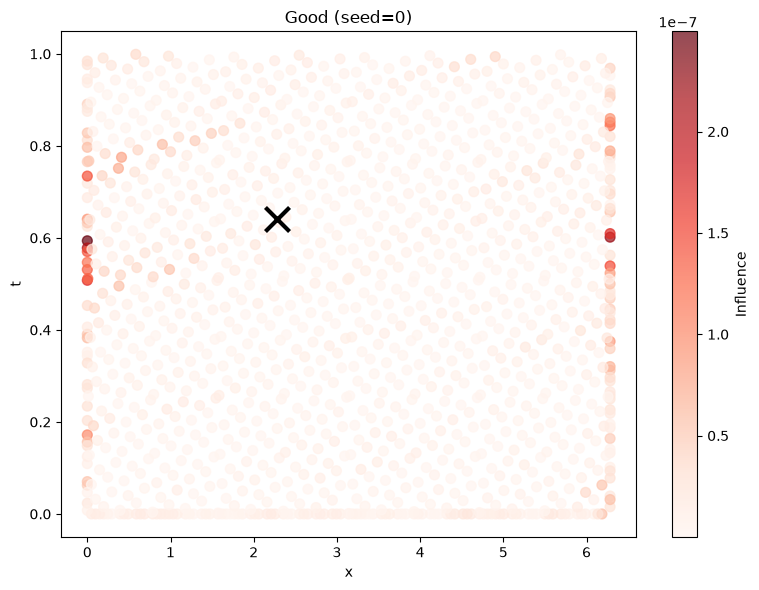

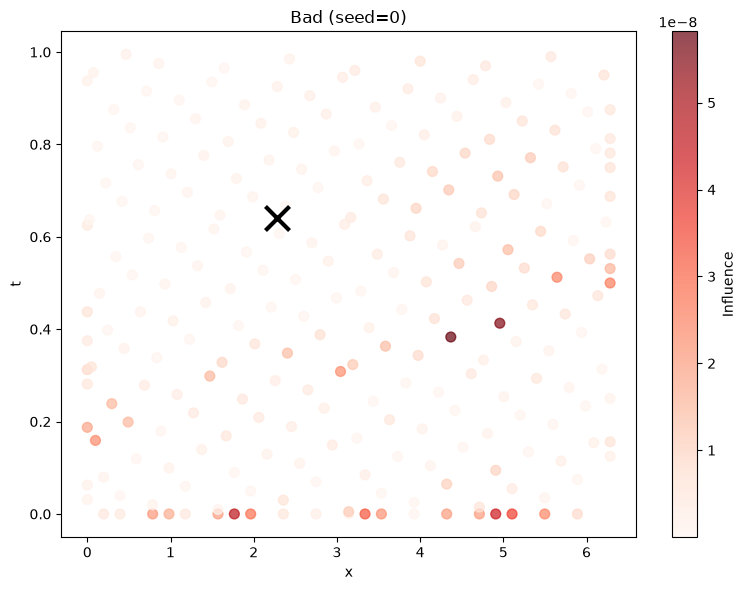

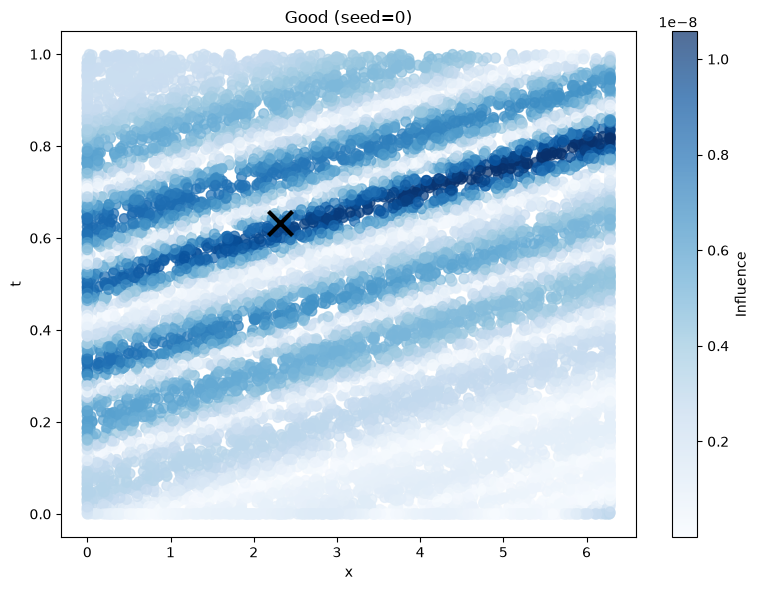

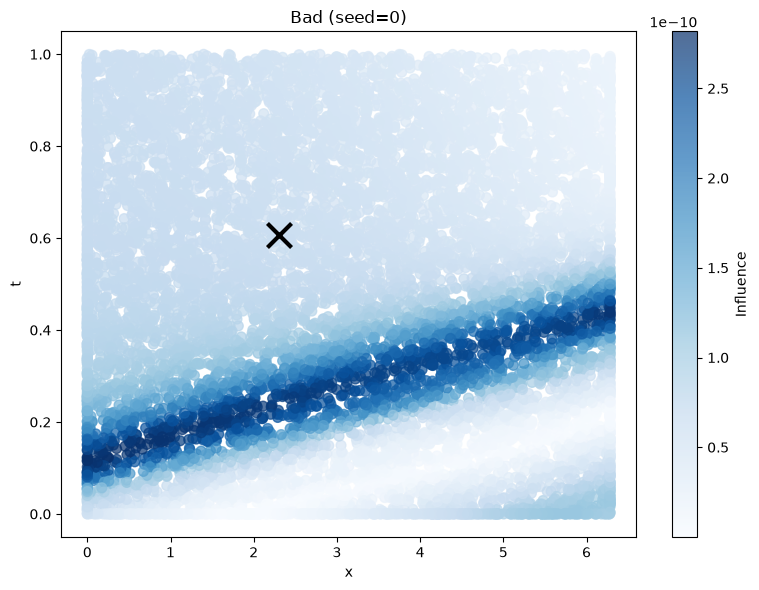

In [8]:
# select random points 
target_coords = np.random.rand(5, 2) * np.array([2 * np.pi, 1.0])

for coords in target_coords:
    print(f"\nVisualizing influences for test point at x={coords[0]:.3f}, t={coords[1]:.3f}")
    
    # visualize influences for given test point
    fig_good, fig_bad = visualize_influence_comparison(
        target_coords=coords,
        left_term='output_0',
        right_term='total_loss',
        problem_name=problem_name,
        seed=seed,
        use_test_points=True,
        figsize=(8, 6),
        model_zoo_base=str(model_zoo),
        alpha=0.7,
    )
    
    plt.show()

    # visualize influences of closest training point
    fig_good, fig_bad = visualize_influence_comparison(
        target_coords=coords,
        left_term='output_0',
        right_term='total_loss',
        problem_name=problem_name,
        seed=seed,
        use_test_points=False,
        figsize=(8, 6),
        model_zoo_base=str(model_zoo),
        alpha=0.7
    )
    
    plt.show()

## Point-wise heatmaps with signs


Visualizing influences for test point at x=1.056, t=0.311


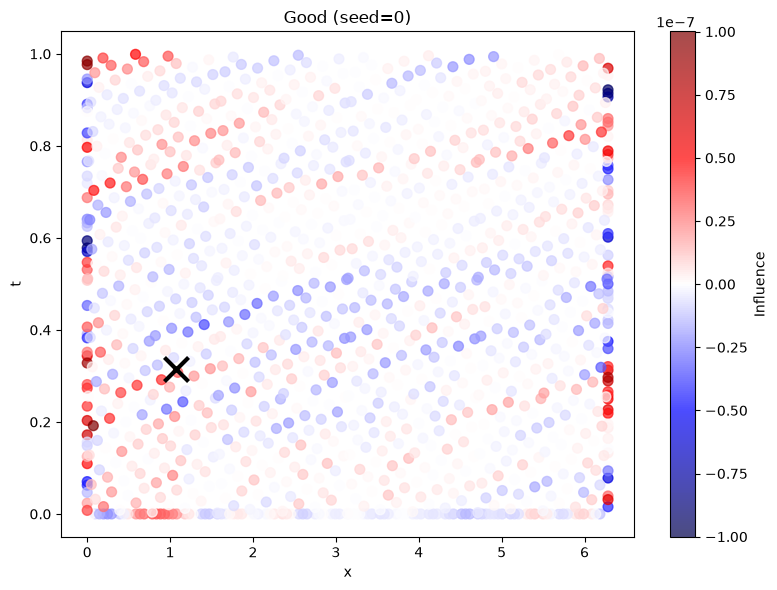

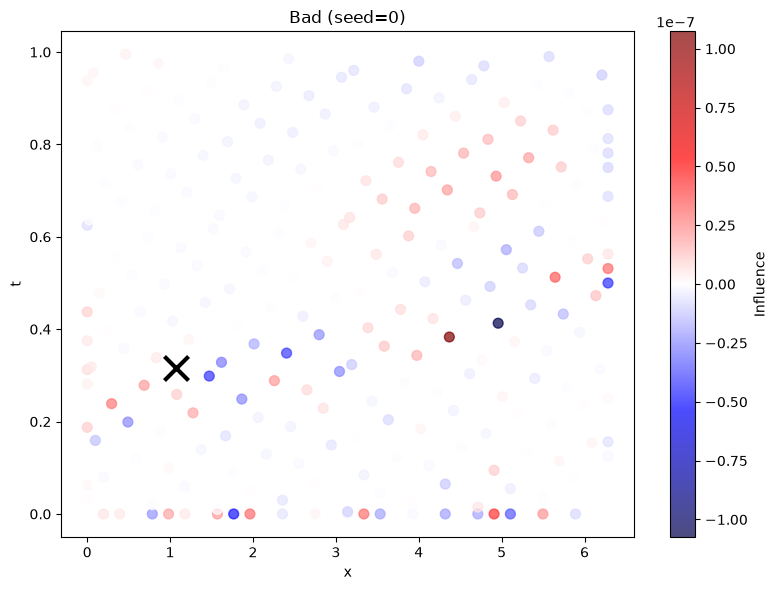

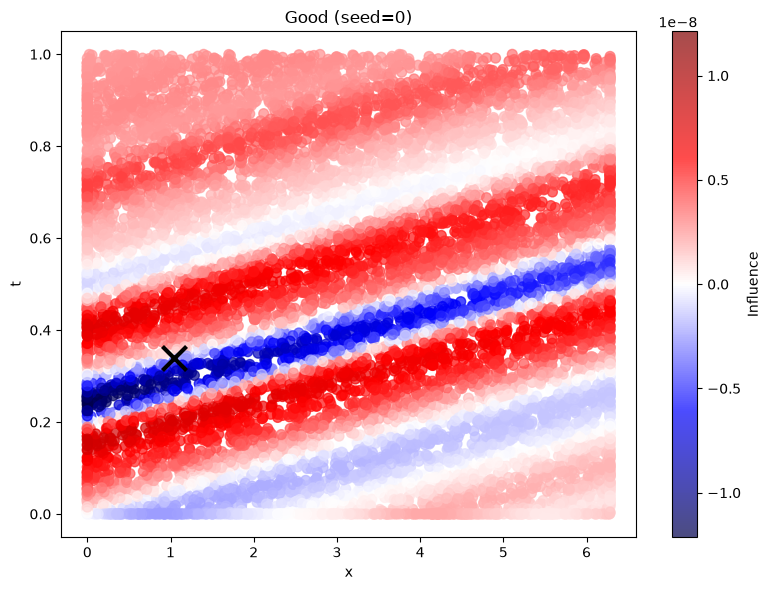

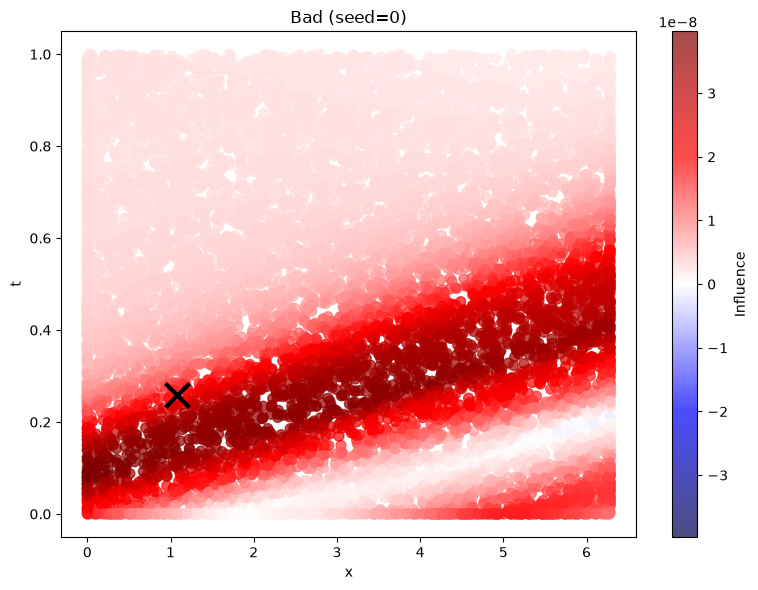


Visualizing influences for test point at x=4.170, t=0.639


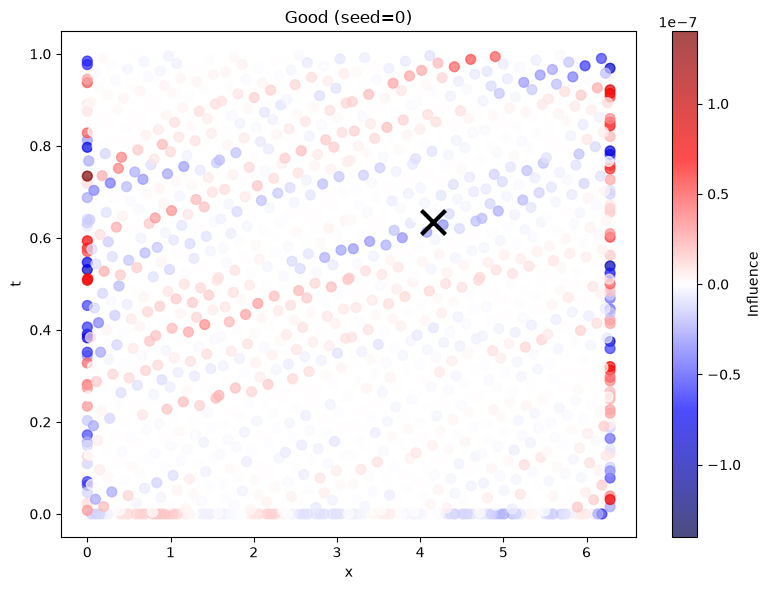

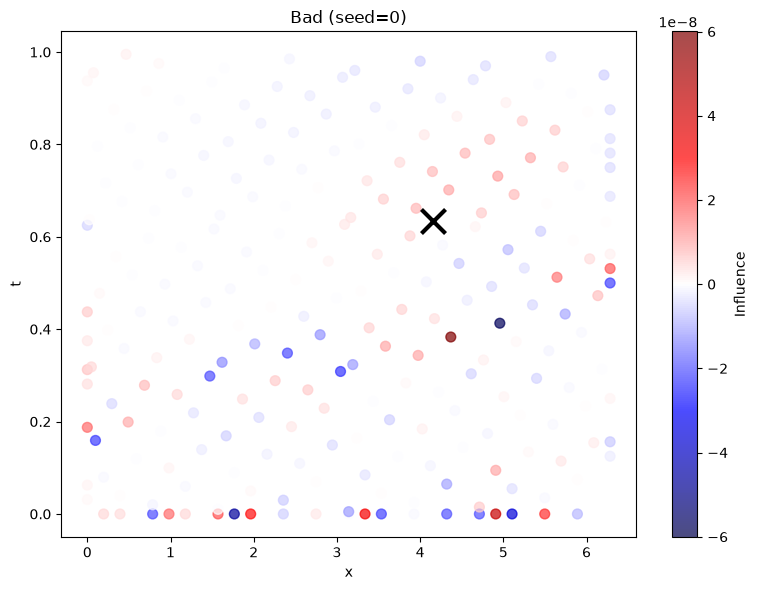

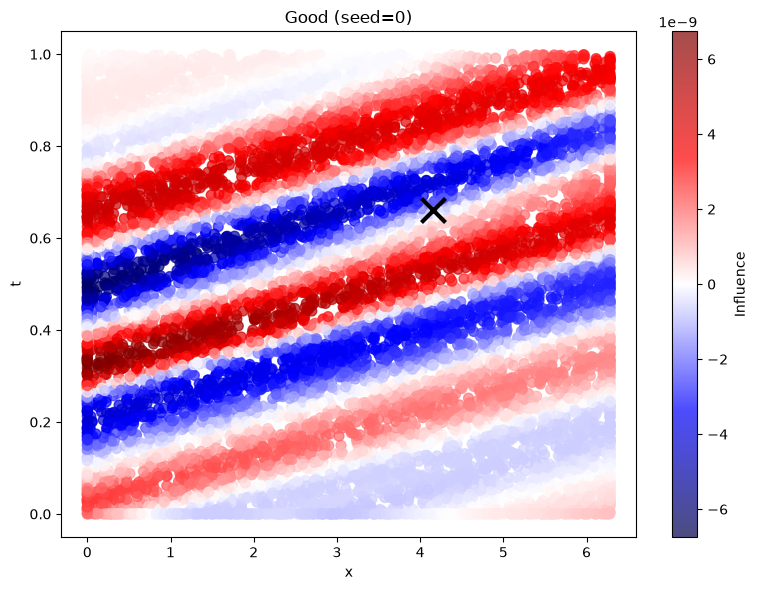

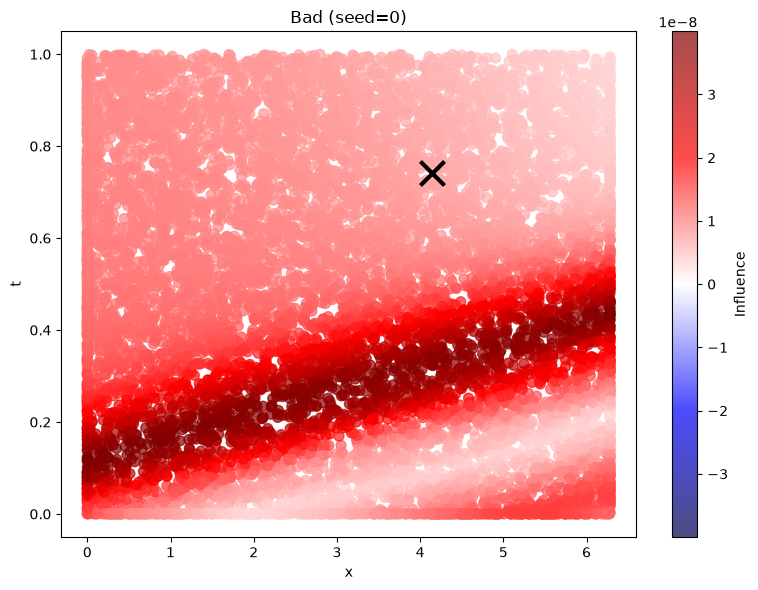


Visualizing influences for test point at x=2.437, t=0.525


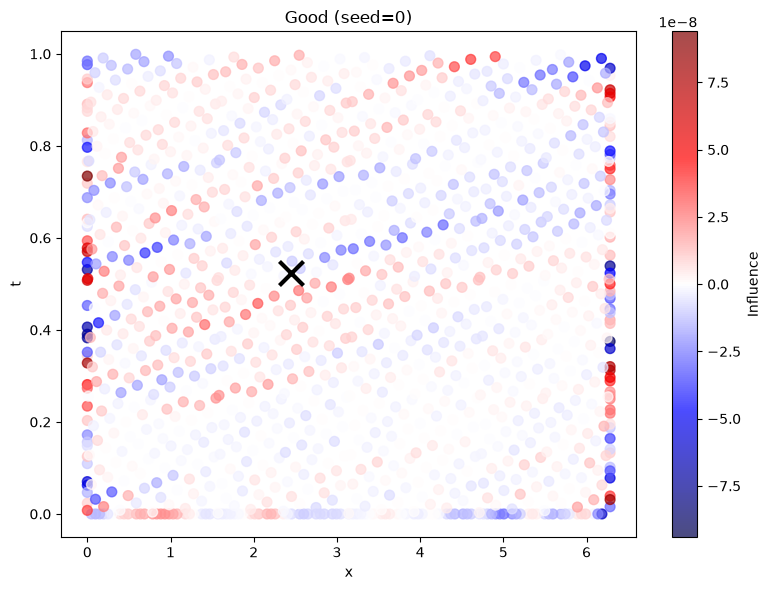

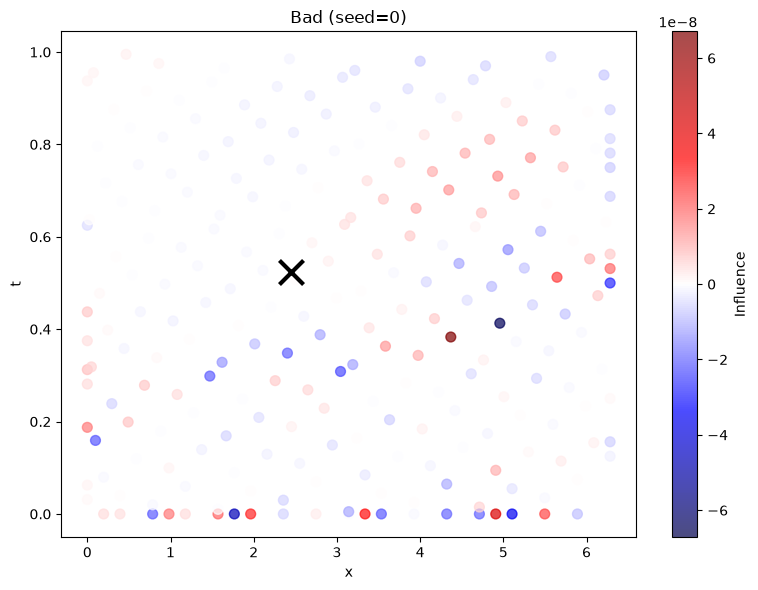

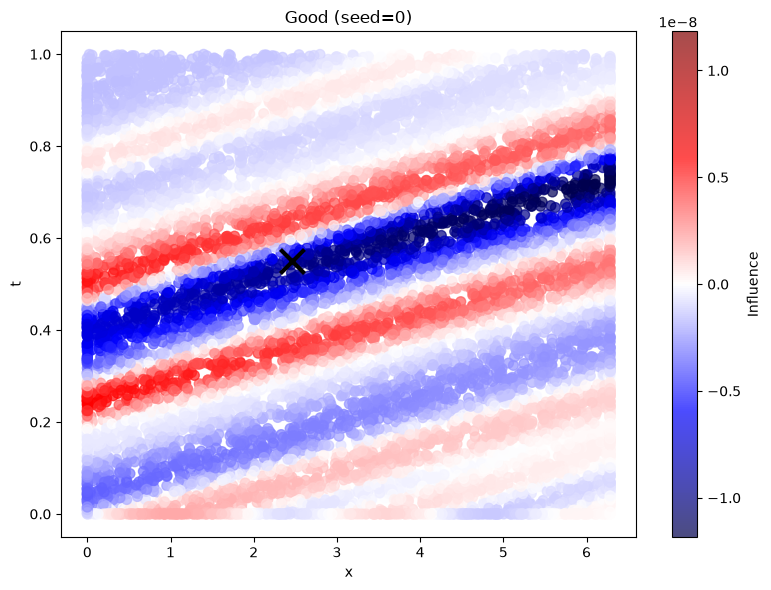

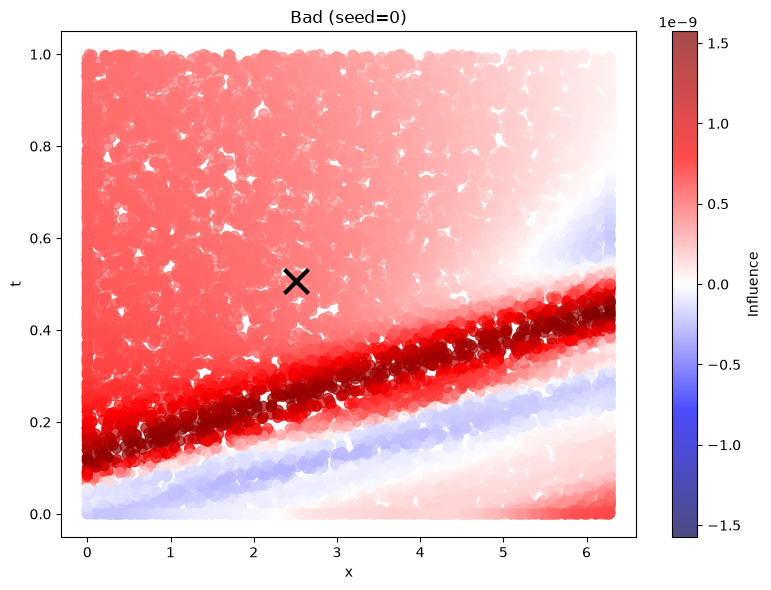


Visualizing influences for test point at x=5.556, t=0.347


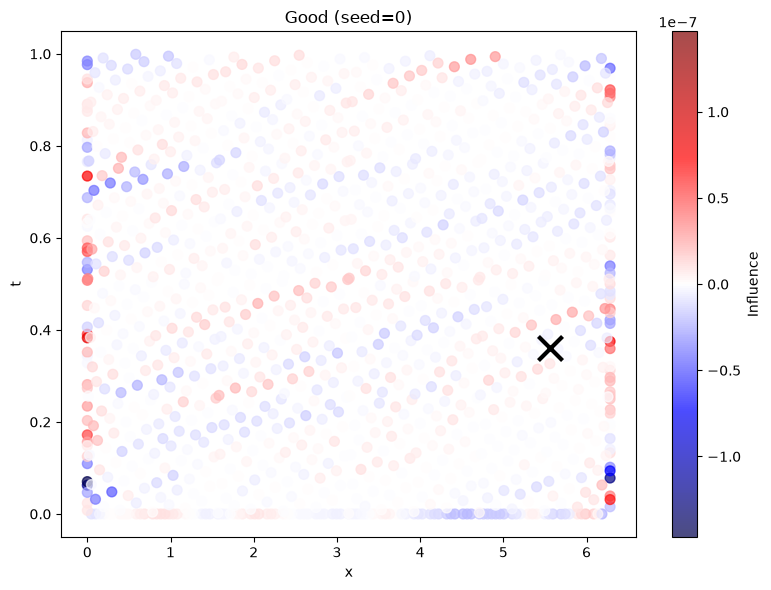

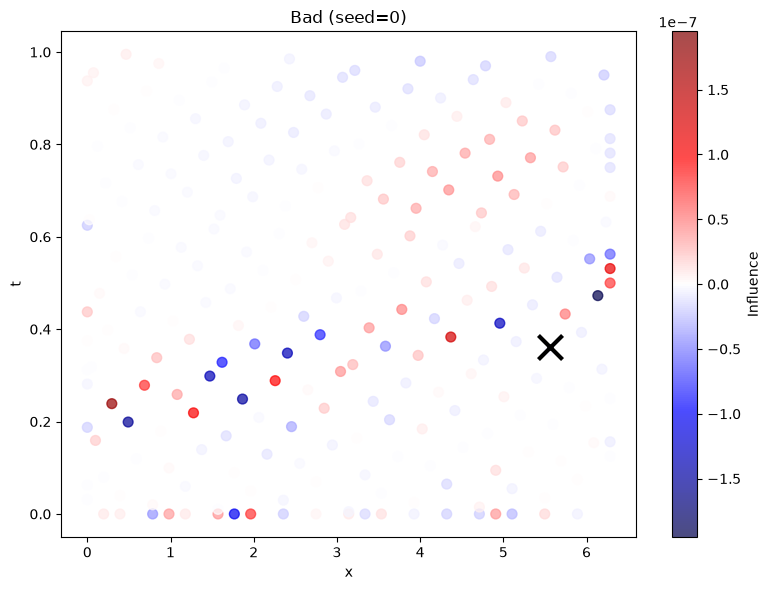

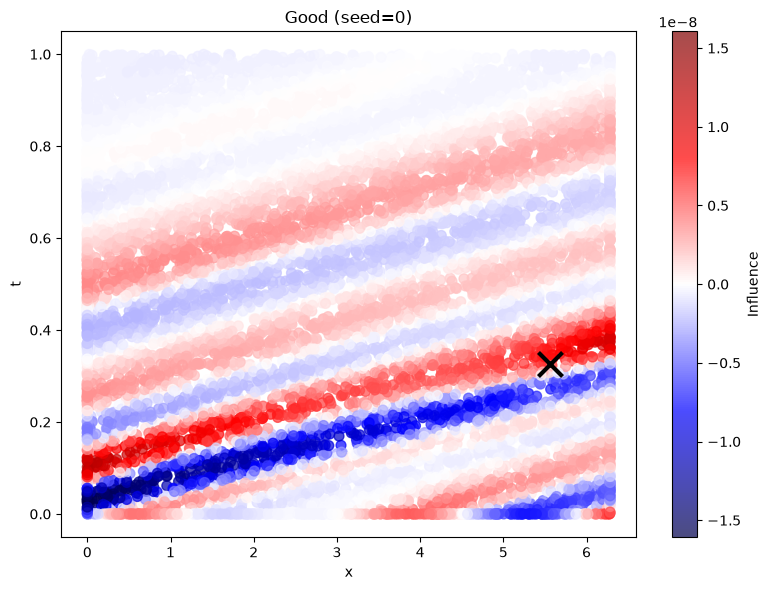

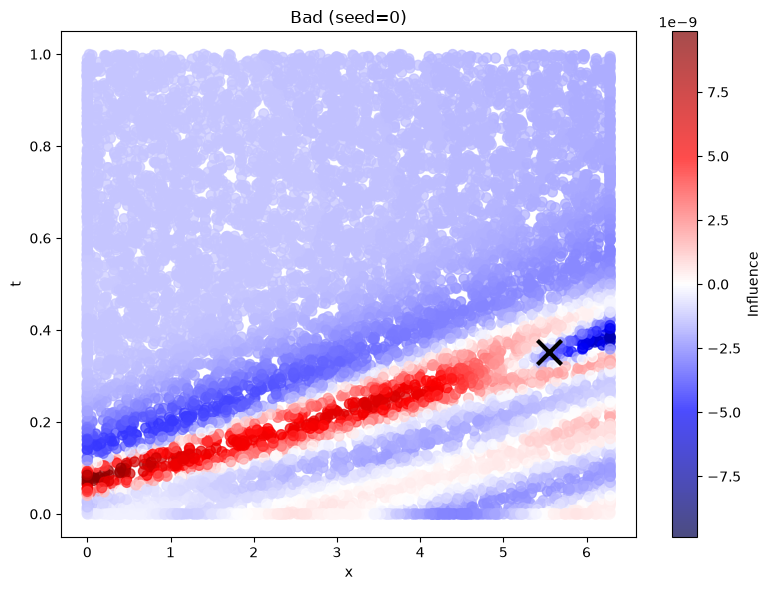


Visualizing influences for test point at x=1.690, t=0.469


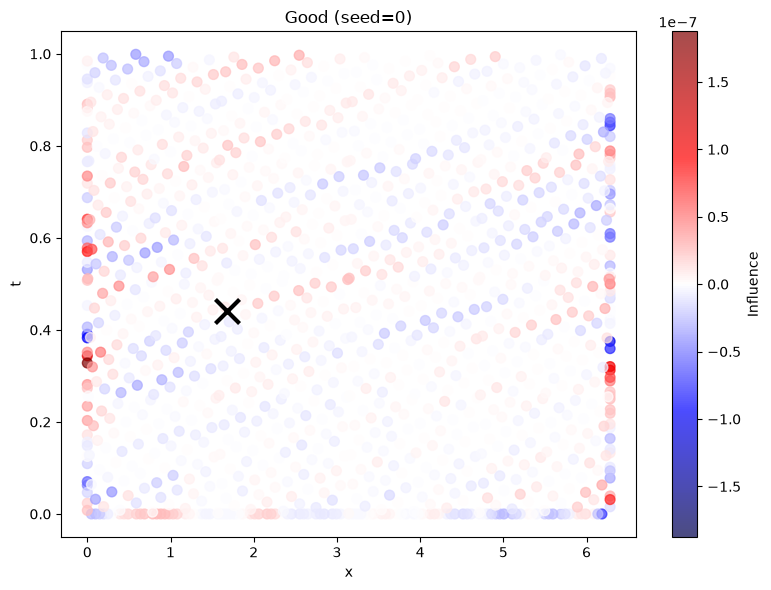

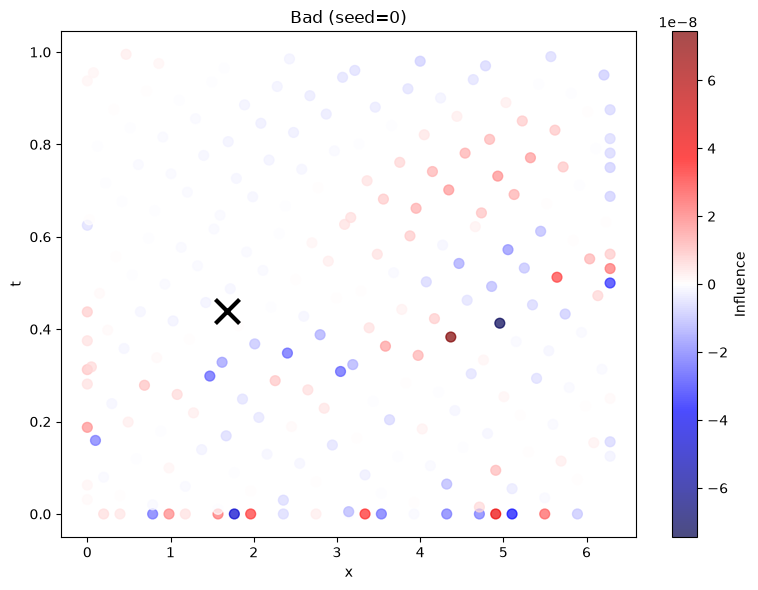

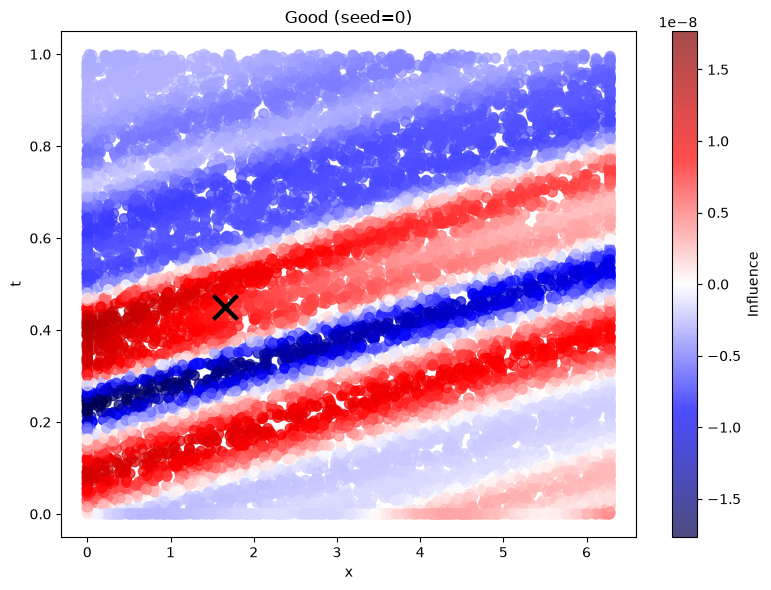

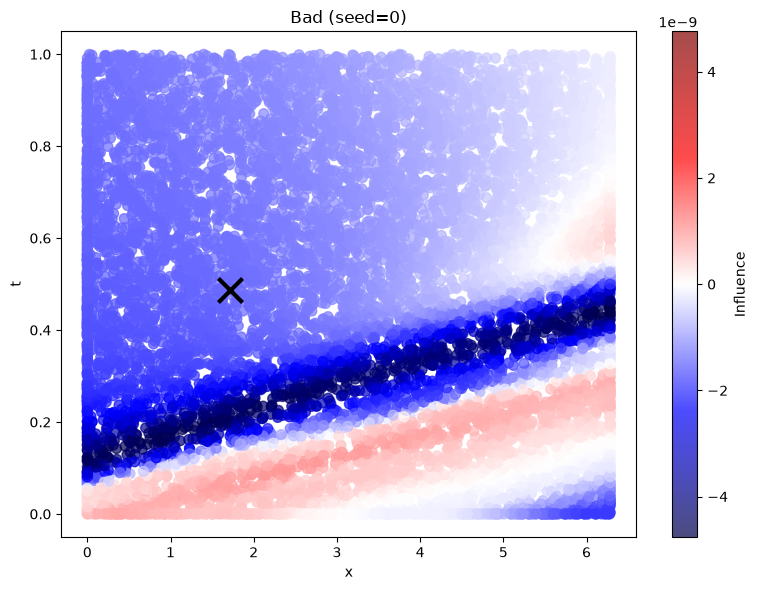

In [9]:
# select random points 
target_coords = np.random.rand(5, 2) * np.array([2 * np.pi, 1.0])

for coords in target_coords:
    print(f"\nVisualizing influences for test point at x={coords[0]:.3f}, t={coords[1]:.3f}")
    
    # visualize influences for given test point
    fig_good, fig_bad = visualize_influence_comparison(
        target_coords=coords,
        left_term='output_0',
        right_term='total_loss',
        problem_name=problem_name,
        seed=seed,
        use_test_points=True,
        figsize=(8, 6),
        model_zoo_base=str(model_zoo),
        alpha=0.7,
        absolute=False, 
    )
    
    plt.show()

    # visualize influences of closest training point
    fig_good, fig_bad = visualize_influence_comparison(
        target_coords=coords,
        left_term='output_0',
        right_term='total_loss',
        problem_name=problem_name,
        seed=seed,
        use_test_points=False,
        figsize=(8, 6),
        model_zoo_base=str(model_zoo),
        alpha=0.7,
        absolute=False, 
    )
    
    plt.show()

## Manual analysis

You can find the calculated influence matrix of shape `[n_test, n_train]` at the following location:

In [10]:
infl_file = np.load(model_zoo / f"{problem_name}_float64" / f"{model_name}_influence_scores" / f"influences_{right_term}_{left_term}.npz")

infl_scores = infl_file['scores']
test_x = infl_file['candidate_points']
train_x = model.data.train_x_all

In [11]:
# [n_candidate_points, n_train_points]
infl_scores.shape

(10000, 1200)

In [12]:
# influences for test point at index 0
infl_scores[0, :]

array([-4.5863521e-06, -5.1836932e-06, -6.3975081e-06, ...,
       -1.4995775e-05, -6.6300299e-06,  2.5864496e-05], dtype=float32)

In [13]:
# influences between x, z
infl_scores[
    100, # test idx
    50, # train idx
]

-1.3843187e-05

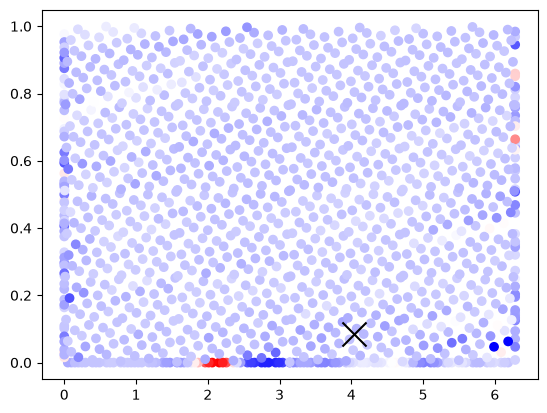

In [14]:
test_idx = 100
plt.scatter(
    *train_x.T,
    c=infl_scores[test_idx, :],
    cmap='bwr',
)

plt.scatter(
    *test_x[test_idx].T, 
    c='black',
    marker='x',
    s=300,
)